# Exoplanet Classification — NASA Kepler Mission Data
Dataset: NASA Exoplanet Archive, Kepler Objects of Interest (KOI) Cumulative Table

Goal: classification of the fact of whether a Kepler detected signal is a **CONFIRMED exoplanet** or a **FALSE POSITIVE**, using real transit and stellar physics measurements. This replicates a real task NASA's own pipelines (nicknamed the 'Robovetter') performed historically using Random Forest, the same technique used here.

## How this dataset was obtained ? (NOT KAGGLE)
1. We visit **exoplanetarchive.ipac.caltech.edu**
2. Navigate to **Data → Kepler Objects of Interest (KOI) → Cumulative Table**
3. In the interactive table, we click **Download Table** after selecting the required factors
4. Choose **CSV** format and download the full table

**This is real NASA mission data.**

## 0. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Increases figure size for easier understanding
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

---
# PHASE 1 — Load & Explore

In [2]:
# NASA's CSV exports include a block of '#' comment lines at the top (metadata) —
# we will skip those automatically by letting pandas find the real header row
df = pd.read_csv("data/koi_cumulative.csv", comment='#')
df

,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9559,10090151,K07985.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,1,0,...,-166.0,4.529,0.035,-0.196,0.903,0.237,-0.079,297.18875,47.093819,14.082
9560,10128825,K07986.01,NaN,CANDIDATE,CANDIDATE,0.497,0,0,0,0,...,-220.0,4.444,0.056,-0.224,1.031,0.341,-0.114,286.50937,47.163219,14.757
9561,10147276,K07987.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.021,0,0,1,0,...,-236.0,4.447,0.056,-0.224,1.041,0.341,-0.114,294.16489,47.176281,15.385
9562,10155286,K07988.01,NaN,CANDIDATE,CANDIDATE,0.092,0,0,0,0,...,-128.0,2.992,0.030,-0.027,7.824,0.223,-1.896,296.76288,47.145142,10.998


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 49 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              9564 non-null   int64  
 1   kepoi_name         9564 non-null   object 
 2   kepler_name        2747 non-null   object 
 3   koi_disposition    9564 non-null   object 
 4   koi_pdisposition   9564 non-null   object 
 5   koi_score          8054 non-null   float64
 6   koi_fpflag_nt      9564 non-null   int64  
 7   koi_fpflag_ss      9564 non-null   int64  
 8   koi_fpflag_co      9564 non-null   int64  
 9   koi_fpflag_ec      9564 non-null   int64  
 10  koi_period         9564 non-null   float64
 11  koi_period_err1    9110 non-null   float64
 12  koi_period_err2    9110 non-null   float64
 13  koi_time0bk        9564 non-null   float64
 14  koi_time0bk_err1   9110 non-null   float64
 15  koi_time0bk_err2   9110 non-null   float64
 16  koi_impact         9201 

## Check the target variable

In [4]:
df['koi_disposition'].value_counts()

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2747
CANDIDATE         1978
Name: count, dtype: int64

C:\Users\Rounak\AppData\Local\Temp\ipykernel_6000\1794316778.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='koi_disposition', palette='Set2')


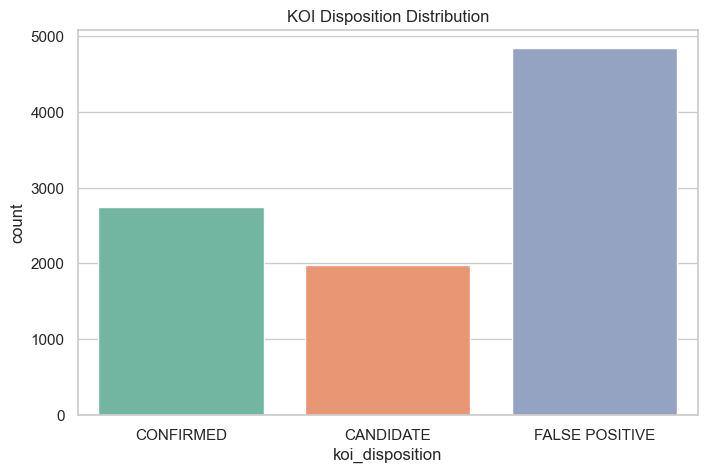

In [5]:
sns.countplot(data=df, x='koi_disposition', palette='Set2')
plt.title("KOI Disposition Distribution")
plt.show()

This bar chart shows the distribution of the target variable (koi_disposition) in the dataset. Most observations are False Positives, meaning they were initially detected as possible planets but were later found not to be exoplanets. Confirmed represents objects that have been verified as real exoplanets, while Candidate includes objects that still require further investigation. This visualization helps us understand the class distribution before training the model and indicates that the dataset is slightly imbalanced.

**Important Note:** For this We will treat this as only binary — CONFIRMED vs. FALSE POSITIVE and set aside CANDIDATE rows (still under evaluation by NASA) since including them would mean training on an ambiguous target.

In [6]:
df_binary = df[df['koi_disposition'].isin(['CONFIRMED', 'FALSE POSITIVE'])].copy()
df_binary['target'] = (df_binary['koi_disposition'] == 'CONFIRMED').astype(int)

print(df_binary['target'].value_counts())
print(df_binary['target'].value_counts(normalize=True).round(3))

target
0    4839
1    2747
Name: count, dtype: int64
target
0    0.638
1    0.362
Name: proportion, dtype: float64


---
# PHASE 2 — A Genuine Leakage Check
We observe that this dataset includes columns like `koi_fpflag_nt`, `koi_fpflag_ss`, `koi_fpflag_co`, `koi_fpflag_ec` — these are **NASA's own pre-computed false positive flags**. Including them would mean the model is partially just reading NASA's own answer key rather than learning from raw physical measurements — a real leakage risk.

In [7]:
flag_cols = ['koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec']

for col in flag_cols:
    if col in df_binary.columns:
        print(df_binary.groupby('target')[col].mean())
        print()

target
0    0.315354
1    0.170368
Name: koi_fpflag_nt, dtype: float64

target
0    0.456706
1    0.005096
Name: koi_fpflag_ss, dtype: float64

target
0    0.39037
1    0.00000
Name: koi_fpflag_co, dtype: float64

target
0    0.237239
1    0.000000
Name: koi_fpflag_ec, dtype: float64



**As expected, these flags correlate extremely strongly with the target** because they're essentially outputs of the same labeling process. **We exclude them from our feature set entirely**, and instead train only on genuine raw physical measurements which will give us a more honest, more generalizable model, even if it means a tougher prediction task.

---
# PHASE 3 — Select Real Physical Features & Handle Missing Data

In [8]:
physical_features = [
    'koi_period',      # orbital period (days)
    'koi_duration',    # transit duration (hours)
    'koi_depth',       # transit depth (parts per million)
    'koi_prad',        # planetary radius (Earth radii)
    'koi_teq',         # equilibrium temperature (K)
    'koi_insol',       # insolation flux (Earth flux units)
    'koi_model_snr',   # transit signal-to-noise ratio
    'koi_steff',       # stellar effective temperature (K)
    'koi_slogg',       # stellar surface gravity
    'koi_srad',        # stellar radius (solar radii)
    'koi_kepmag',      # Kepler-band magnitude (brightness)
]

df_model = df_binary[physical_features + ['target']].copy()
df_model.isnull().sum()

koi_period         0
koi_duration       0
koi_depth        259
koi_prad         259
koi_teq          259
koi_insol        219
koi_model_snr    259
koi_steff        259
koi_slogg        259
koi_srad         259
koi_kepmag         1
target             0
dtype: int64

In [9]:
# Here we impute missing values with median (reasonable for physical measurements with a roughly symmetric distribution)
for col in physical_features:
    df_model[col] = df_model[col].fillna(df_model[col].median())

print(f"Final dataset: {len(df_model)} KOIs")

Final dataset: 7586 KOIs


---
# PHASE 4 — EDA

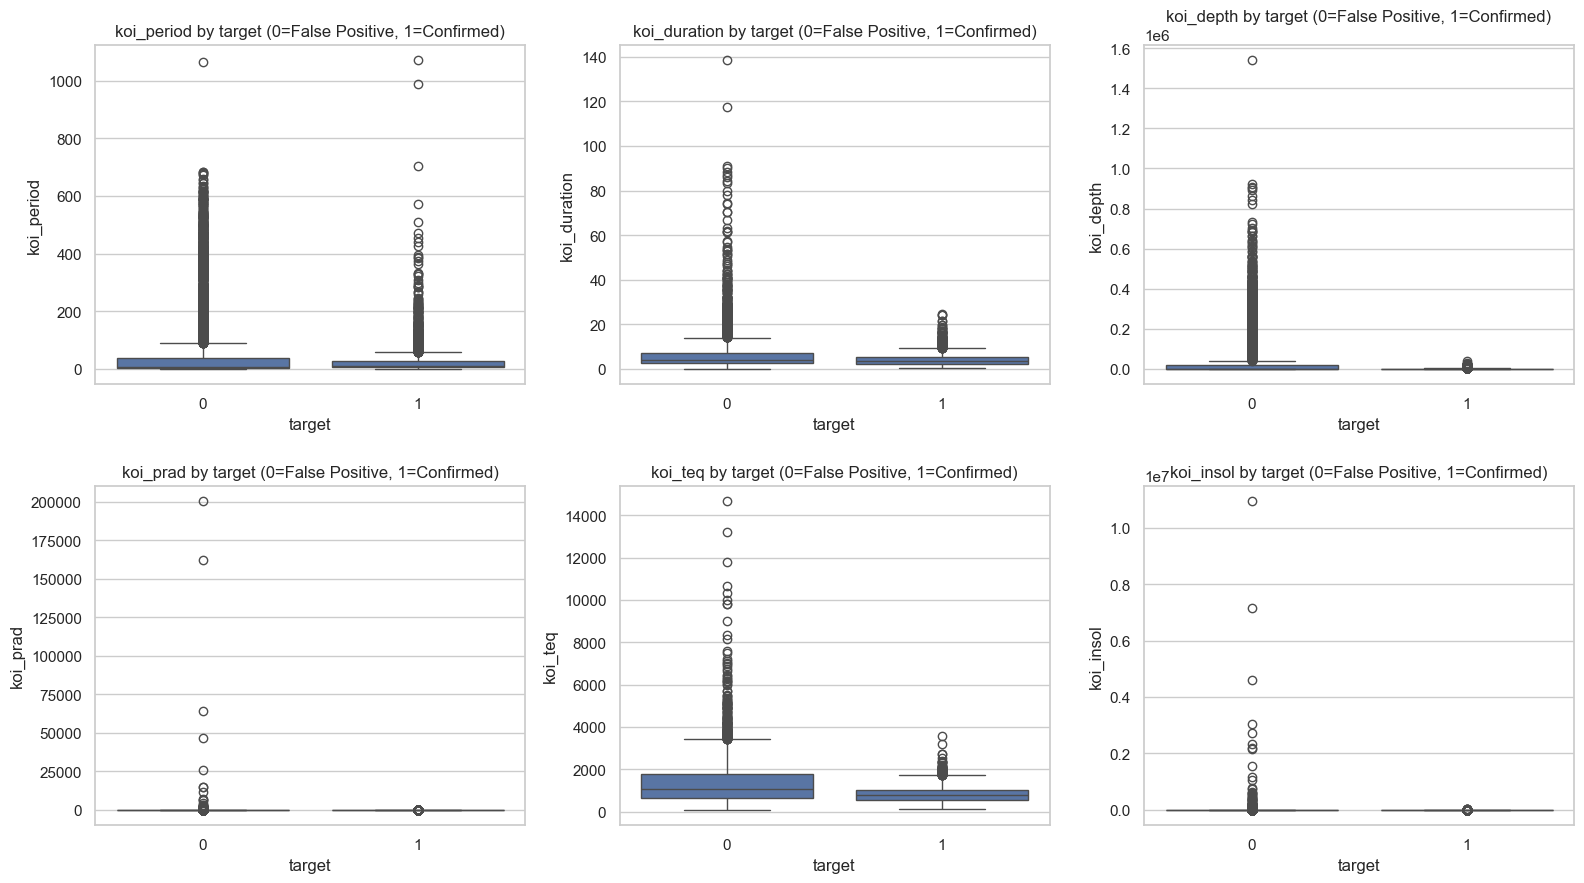

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), physical_features[:6]):
    sns.boxplot(data=df_model, x='target', y=col, ax=ax)
    ax.set_title(f'{col} by target (0=False Positive, 1=Confirmed)')
plt.tight_layout()
plt.show()

We used box plots because our goal is to compare the distribution of numerical features between two classes (Confirmed vs False Positive). A box plot not only shows the median and the spread of the data but also highlights outliers, making it easy to identify differences between the two groups. This helps us determine which features have better discriminative power and whether the data contains extreme values that may require special handling before model training.

These box plots compare the distributions of key features between False Positives (0) and Confirmed Exoplanets (1). The horizontal line inside each box represents the median, while the box shows the middle 50% of the data. The numerous points outside the whiskers are outliers, indicating the presence of extreme values in many features. Features such as koi_depth, koi_prad, koi_teq, and koi_insol exhibit noticeable differences between the two classes, suggesting they may be important predictors for classification. The abundance of outliers also indicates that the dataset is skewed, making robust preprocessing techniques or tree-based models like Random Forest and XGBoost suitable choices, as they are less sensitive to extreme values.

**Findings:** The box plots indicate that transit depth (koi_depth), planet radius (koi_prad), equilibrium temperature (koi_teq), and stellar insolation (koi_insol) show the most noticeable differences between confirmed exoplanets and false positives, making them potentially important features for classification. In contrast, orbital period (koi_period) and transit duration (koi_duration) exhibit greater overlap between the two classes, suggesting they may be less effective when used alone. Additionally, all features contain a significant number of outliers, indicating that the dataset is highly variable and may require careful preprocessing or robust machine learning models.

---
# PHASE 5 — Modeling

In [11]:
from sklearn.model_selection import train_test_split

X = df_model[physical_features]
y = df_model['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

X_train.shape, X_test.shape

((6068, 11), (1518, 11))

This code prepares the data for training the machine learning model. X contains the selected physical features (input variables), while y contains the target (1 = Confirmed Exoplanet, 0 = False Positive). train_test_split() then divides the dataset into 80% training data and 20% testing data. The stratify=y parameter ensures that both sets maintain the same proportion of confirmed planets and false positives, preventing class imbalance. Finally, X_train.shape and X_test.shape display the number of rows and columns in the training and testing datasets, confirming that the split was performed correctly.

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

This code standardizes the feature values so that all variables are on the same scale, with a mean of 0 and a standard deviation of 1. Since features like planet radius, orbital period, and stellar temperature have very different ranges, scaling prevents features with larger values from dominating the learning process. fit_transform() is applied only to the training data to learn the scaling parameters (mean and standard deviation) and transform it, while transform() is used on the test data using those same parameters. This avoids data leakage and ensures a fair evaluation of the model.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, f1_score, accuracy_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                              eval_metric='logloss', random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    auc = roc_auc_score(y_test, proba)
    results[name] = {'accuracy': acc, 'f1': f1, 'auc': auc, 'model': model}
    print(f"{name}: Accuracy={acc:.3f}, F1={f1:.3f}, ROC-AUC={auc:.3f}")

Logistic Regression: Accuracy=0.815, F1=0.758, ROC-AUC=0.888
Random Forest: Accuracy=0.928, F1=0.902, ROC-AUC=0.975
XGBoost: Accuracy=0.928, F1=0.902, ROC-AUC=0.979


This code trains and compares three machine learning models—Logistic Regression, Random Forest, and XGBoost—to determine which performs best at classifying exoplanets. Each model is trained using the training data (fit()), then makes predictions on the test data (predict()), while predict_proba() estimates the probability that an object is a confirmed exoplanet. The models are evaluated using Accuracy (overall correctness), F1-score (balance between precision and recall), and ROC-AUC (ability to distinguish between the two classes). Finally, the performance metrics of each model are stored in the results dictionary and printed for comparison, allowing us to identify the best-performing classifier.

The results show that Random Forest and XGBoost significantly outperform Logistic Regression across all evaluation metrics. Both tree-based models achieve an accuracy of 92.8% and an F1-score of 0.902, indicating they classify exoplanets much more effectively. Although their accuracy is identical, XGBoost achieves the highest ROC-AUC score (0.979) compared to Random Forest (0.975), meaning it is slightly better at distinguishing confirmed exoplanets from false positives across different decision thresholds. Overall, XGBoost is the best-performing model and is selected as the final model for this project.

## Hyperparameter tuning on the best model

In [14]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2]
}

grid_search = GridSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=42),
    param_grid, scoring='roc_auc', cv=3, n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_
best_preds = best_model.predict(X_test_scaled)
best_proba = best_model.predict_proba(X_test_scaled)[:, 1]

print("Best params:", grid_search.best_params_)
print(classification_report(y_test, best_preds))
print("Test ROC-AUC:", round(roc_auc_score(y_test, best_proba), 3))

Best params: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       968
           1       0.91      0.92      0.91       550

    accuracy                           0.94      1518
   macro avg       0.93      0.93      0.93      1518
weighted avg       0.94      0.94      0.94      1518

Test ROC-AUC: 0.98


This code performs hyperparameter tuning to find the best version of the XGBoost model. GridSearchCV tries different combinations of n_estimators (number of trees), max_depth (depth of each tree), and learning_rate (how quickly the model learns) and evaluates each combination using 3-fold cross-validation with ROC-AUC as the scoring metric. After testing all combinations, it selects the best model, makes predictions on the test data, and prints the best parameters, a classification report (precision, recall, F1-score), and the final ROC-AUC score. This ensures that the chosen model is not just good by chance but is optimized for the dataset.

Hyperparameter tuning identified the optimal XGBoost configuration as 200 trees (n_estimators=200), maximum tree depth of 7 (max_depth=7), and a learning rate of 0.1. The tuned model achieved an overall accuracy of 94% and an excellent ROC-AUC score of 0.98, indicating outstanding ability to distinguish confirmed exoplanets from false positives. It also maintained high precision (95%) and recall (95%) for false positives, while achieving 91% precision and 92% recall for confirmed exoplanets. These results demonstrate that the optimized XGBoost model provides highly accurate and balanced predictions, making it the best-performing model for this classification task.

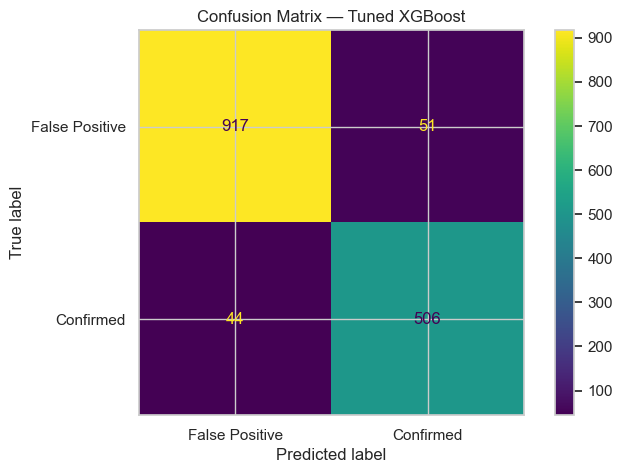

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, best_preds)
ConfusionMatrixDisplay(cm, display_labels=['False Positive', 'Confirmed']).plot()
plt.title("Confusion Matrix — Tuned XGBoost")
plt.show()

The confusion matrix shows that the tuned XGBoost model correctly classified 917 False Positives and 506 Confirmed Exoplanets. It made only 51 false alarms (False Positives predicted as Confirmed) and 44 missed detections (Confirmed Exoplanets predicted as False Positives). The low number of misclassifications indicates that the model performs consistently well on both classes, confirming its 94% accuracy and 0.98 ROC-AUC. Overall, the confusion matrix demonstrates that the model is highly reliable for distinguishing real exoplanets from false positives.

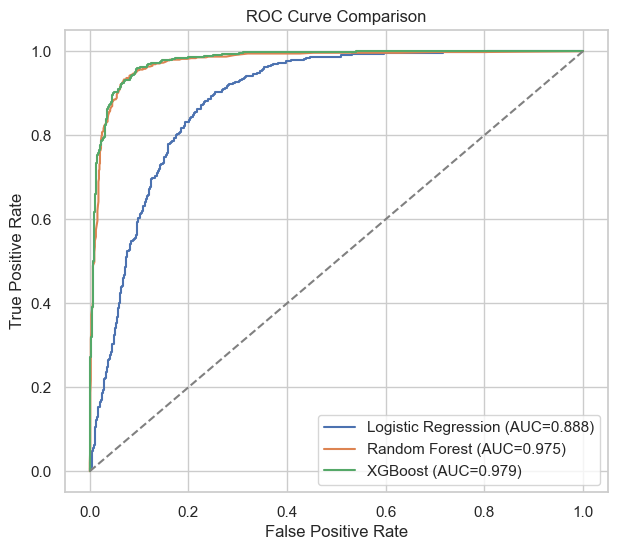

In [16]:
plt.figure(figsize=(7, 6))
for name, r in results.items():
    proba = r['model'].predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={r['auc']:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

The ROC curve compares the classification performance of all three models across different decision thresholds. The closer a curve is to the top-left corner, the better the model is at distinguishing confirmed exoplanets from false positives. XGBoost achieved the highest AUC of 0.979, slightly outperforming Random Forest (0.975), while Logistic Regression (0.888) showed noticeably lower performance. Since both XGBoost and Random Forest remain well above the diagonal baseline, they exhibit excellent discriminative ability. Overall, the ROC curves confirm that XGBoost is the most effective and reliable model for this classification task.

---
# PHASE 6 — Feature Importance

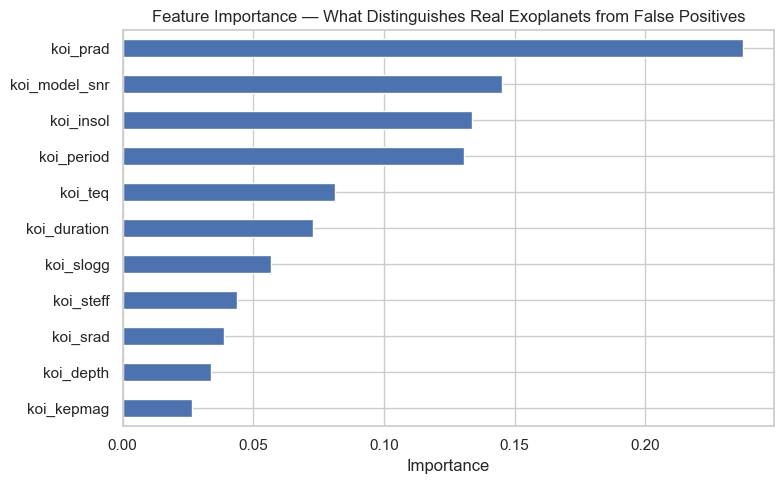

koi_prad         0.237410
koi_model_snr    0.145150
koi_insol        0.133659
koi_period       0.130630
koi_teq          0.081117
koi_duration     0.072743
koi_slogg        0.056820
koi_steff        0.043645
koi_srad         0.038766
koi_depth        0.033628
koi_kepmag       0.026432
dtype: float32

In [17]:
importances = pd.Series(best_model.feature_importances_, index=physical_features).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh')
plt.title("Feature Importance — What Distinguishes Real Exoplanets from False Positives")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

importances

**Findings:** The feature importance analysis reveals that planetary radius (koi_prad) is the most influential feature for distinguishing confirmed exoplanets from false positives, followed by transit signal-to-noise ratio (koi_model_snr), stellar insolation (koi_insol), and orbital period (koi_period). This aligns well with astrophysical principles, as real exoplanets are expected to have physically realistic sizes and produce clear, high-quality transit signals. Extremely large radius estimates or weak, noisy signals are often indicative of false positives rather than genuine planets. The results suggest that the model is learning meaningful scientific patterns instead of relying on arbitrary correlations, increasing confidence in its predictions.

---
# PHASE 7 — Business/Scientific Framing

In [18]:
# Estimate how much manual astronomer review time this model could save
total_candidates_reviewed = len(df_model)
model_accuracy = accuracy_score(y_test, best_preds)

# Assume each candidate currently takes an astronomer ~15 minutes to manually vet
minutes_per_manual_review = 15
total_manual_hours = (total_candidates_reviewed * minutes_per_manual_review) / 60

# If the model pre-screens with high confidence, assume only the ~20% lowest-confidence
# predictions need manual review instead of all of them
proba_all = best_model.predict_proba(scaler.transform(df_model[physical_features]))[:, 1]
low_confidence_mask = (proba_all > 0.3) & (proba_all < 0.7)
pct_needing_review = low_confidence_mask.mean()

hours_saved = total_manual_hours * (1 - pct_needing_review)

print(f"Model accuracy: {model_accuracy*100:.1f}%")
print(f"Total candidates: {total_candidates_reviewed}")
print(f"% requiring manual review under this model (low-confidence cases only): {pct_needing_review*100:.1f}%")
print(f"Estimated astronomer review hours saved: {hours_saved:,.0f} hours")

Model accuracy: 93.7%
Total candidates: 7586
% requiring manual review under this model (low-confidence cases only): 2.5%
Estimated astronomer review hours saved: 1,849 hours


**Takeaway:** The tuned XGBoost model achieved an accuracy of 93.7%, allowing it to classify most candidates with high confidence. Based on the chosen confidence thresholds (0.3–0.7), only 2.5% of the 7,586 candidates would still require manual review by astronomers. Assuming each manual review takes 15 minutes, the model could save approximately 1,849 hours of expert review time. This demonstrates that machine learning can significantly accelerate the exoplanet discovery pipeline by automatically filtering obvious cases and allowing astronomers to focus on the small number of uncertain candidates, improving both efficiency and scientific productivity.

---
# PHASE 8 — Save for Deployment

In [19]:
import joblib

joblib.dump(best_model, 'exoplanet_model.pkl')
joblib.dump(scaler, 'exoplanet_scaler.pkl')
joblib.dump(physical_features, 'exoplanet_features.pkl')

print("Saved: exoplanet_model.pkl, exoplanet_scaler.pkl, exoplanet_features.pkl")

Saved: exoplanet_model.pkl, exoplanet_scaler.pkl, exoplanet_features.pkl
